# 2.2 Arquitecturas

Tres arquitecturas (`src/models.py`), todas con las entradas estáticas concatenadas al resumen de la secuencia y **dos salidas** (binaria y multiclase) sobre una capa oculta compartida:

- **GRU**: 2 capas, estado final ⊕ estáticas.
- **TCN**: 6 bloques residuales de convoluciones causales dilatadas (dilatación 1, 2, …, 32; kernel 3; campo receptivo 253 h ≥ 168).
- **CNN-LSTM**: dos convoluciones causales (kernel 5) → LSTM → estado final ⊕ estáticas.

**Pérdida combinada:** BCE(binaria) + λ·CE(multiclase) con λ = 1. Las dos cabezas están en escala de logits y comparten la misma prior (la clase "ninguno" coincide con *y*_bin = 0), de modo que sus gradientes son comparables; λ se incluye en la búsqueda de hiperparámetros (notebook 04). En esta etapa se usa pérdida ponderada (ver 03) y L = 72.

**Protocolo:** AdamW (lr 10⁻³, weight decay 10⁻⁴), dropout 0.2, lote 512, máximo 12 épocas, *early stopping* sobre el PR-AUC binario de validación (paciencia 3) y restauración del mejor estado. Semilla 14. Los resultados los produce `entrega2/run_experiments.py` (corridas `arch_*`).

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plots import set_style, savefig

set_style()
pd.set_option("display.precision", 3)
FIG = ROOT / "entrega2" / "figures"
RES = ROOT / "entrega2" / "results"
RUNS = RES / "runs"


def load_run(name):
    m = json.loads((RUNS / name / "metrics.json").read_text())
    m["history"] = pd.read_csv(RUNS / name / "history.csv")
    return m

from src.labels import CLASSES
from src.models import build_model, n_params

ARCHS = {"gru": "GRU", "tcn": "TCN", "cnnlstm": "CNN-LSTM"}
runs = {ARCHS[a]: load_run(f"arch_{a}") for a in ARCHS}
{k: f"{v['n_params']:,} parámetros, {v['epochs']} épocas, mejor época {v['best_epoch']}" for k, v in runs.items()}


{'GRU': '45,014 parámetros, 12 épocas, mejor época 11',
 'TCN': '144,214 parámetros, 8 épocas, mejor época 5',
 'CNN-LSTM': '37,238 parámetros, 12 épocas, mejor época 11'}

## 1. Diagramas de las arquitecturas

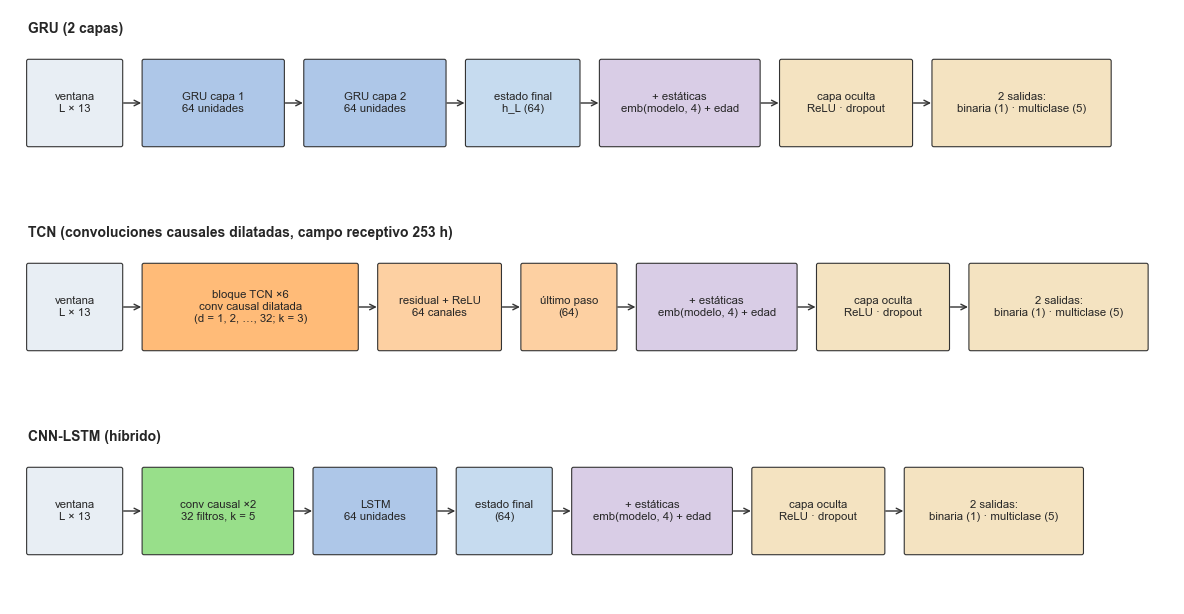

In [2]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

def draw(ax, boxes, title):
    ax.set_xlim(0, 12.6); ax.set_ylim(0, 2); ax.axis("off")
    x = 0.2
    for i, (label, color, w) in enumerate(boxes):
        ax.add_patch(FancyBboxPatch((x, 0.55), w, 0.9, boxstyle="round,pad=0.02", fc=color, ec="#333", lw=0.8))
        ax.text(x + w / 2, 1.0, label, ha="center", va="center", fontsize=8.2)
        x += w + 0.25
        if i < len(boxes) - 1:
            ax.add_patch(FancyArrowPatch((x - 0.25, 1.0), (x, 1.0), arrowstyle="->", mutation_scale=10, color="#333"))
    ax.text(0.2, 1.75, title, fontsize=10, fontweight="bold")

common_in = ("ventana\nL × 13", "#e8eef4", 1.0)
static = ("+ estáticas\nemb(modelo, 4) + edad", "#d9cde6", 1.7)
head = ("capa oculta\nReLU · dropout", "#f4e3c1", 1.4)
outs = ("2 salidas:\nbinaria (1) · multiclase (5)", "#f4e3c1", 1.9)
fig, axes = plt.subplots(3, 1, figsize=(12, 6.3))
draw(axes[0], [common_in, ("GRU capa 1\n64 unidades", "#aec7e8", 1.5), ("GRU capa 2\n64 unidades", "#aec7e8", 1.5),
               ("estado final\nh_L (64)", "#c6dbef", 1.2), static, head, outs], "GRU (2 capas)")
draw(axes[1], [common_in, ("bloque TCN ×6\nconv causal dilatada\n(d = 1, 2, …, 32; k = 3)", "#ffbb78", 2.3),
               ("residual + ReLU\n64 canales", "#fdd0a2", 1.3), ("último paso\n(64)", "#fdd0a2", 1.0), static, head, outs],
     "TCN (convoluciones causales dilatadas, campo receptivo 253 h)")
draw(axes[2], [common_in, ("conv causal ×2\n32 filtros, k = 5", "#98df8a", 1.6), ("LSTM\n64 unidades", "#aec7e8", 1.3),
               ("estado final\n(64)", "#c6dbef", 1.0), static, head, outs], "CNN-LSTM (híbrido)")
plt.tight_layout()
savefig(fig, "02_architectures", FIG)

## 2. Comparación en validación contra la línea base de la Entrega 1

La línea base se lee de `entrega1/results/` (sin reentrenar). El F1 por clase de la línea base se obtiene de su matriz de confusión.

In [3]:
E1 = ROOT / "entrega1" / "results"
base_bin = pd.read_csv(E1 / "baseline_val_binary.csv", index_col=0)
base_conf = pd.read_csv(E1 / "baseline_val_confusion.csv", index_col=[0, 1])


def f1_from_confusion(cm):
    cm = cm.to_numpy()
    tp = np.diag(cm); fp = cm.sum(axis=0) - tp; fn = cm.sum(axis=1) - tp
    return 2 * tp / np.maximum(2 * tp + fp + fn, 1)


rows = []
for name, r in base_bin.iterrows():
    f1 = f1_from_confusion(base_conf.loc[name])
    rows.append({"modelo": name, "tipo": "línea base (E1)", "PR-AUC": r["PR-AUC"], "ROC-AUC": r["ROC-AUC"],
                 "recall@P≥0.80": r["recall@P≥0.80"], "F1 macro": f1.mean(), "parámetros": np.nan, "épocas": np.nan})
for name, m in runs.items():
    rows.append({"modelo": name, "tipo": "deep learning (L = 72, ponderada)", "PR-AUC": m["PR-AUC"], "ROC-AUC": m["ROC-AUC"],
                 "recall@P≥0.80": m["recall@P≥0.80"], "F1 macro": m["f1"]["macro"], "parámetros": m["n_params"],
                 "épocas": m["best_epoch"]})
comp = pd.DataFrame(rows).set_index("modelo")
comp.to_csv(RES / "comparison_architectures.csv")
comp

,tipo,PR-AUC,ROC-AUC,recall@P≥0.80,F1 macro,parámetros,épocas
modelo,,,,,,,
Regresión logística,línea base (E1),0.858,0.998,0.836,0.943,NaN,NaN
LightGBM,línea base (E1),0.999,1.000,1.000,0.996,NaN,NaN
GRU,"deep learning (L = 72, ponderada)",0.994,0.999,0.992,0.964,45014.0,11.0
TCN,"deep learning (L = 72, ponderada)",0.992,1.000,0.991,0.817,144214.0,5.0
CNN-LSTM,"deep learning (L = 72, ponderada)",0.995,1.000,0.991,0.963,37238.0,11.0


## 3. Curvas de aprendizaje

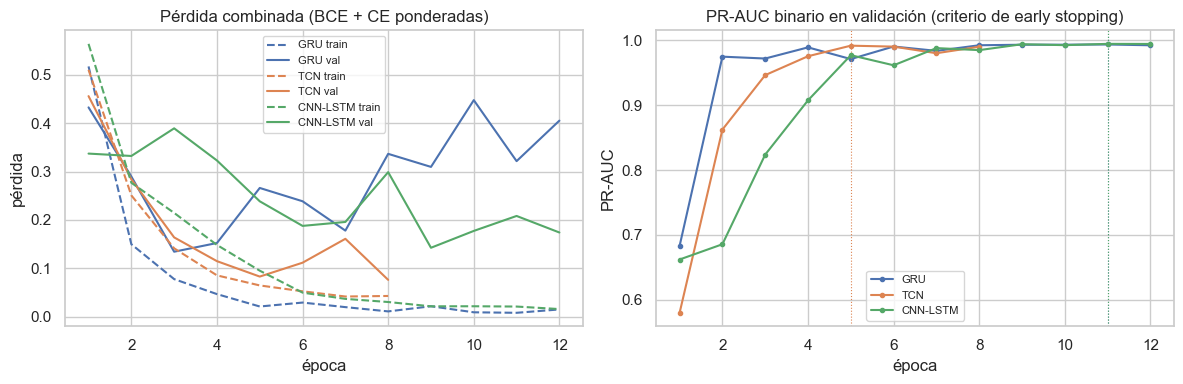

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, m in runs.items():
    h = m["history"]
    axes[0].plot(h["epoch"], h["train_loss"], "--", label=f"{name} train")
    axes[0].plot(h["epoch"], h["val_loss"], "-", color=axes[0].lines[-1].get_color(), label=f"{name} val")
    axes[1].plot(h["epoch"], h["val_pr_auc"], "-o", ms=3, label=name)
    axes[1].axvline(m["best_epoch"], color=axes[1].lines[-1].get_color(), ls=":", lw=0.8)
axes[0].set(title="Pérdida combinada (BCE + CE ponderadas)", xlabel="época", ylabel="pérdida")
axes[1].set(title="PR-AUC binario en validación (criterio de early stopping)", xlabel="época", ylabel="PR-AUC")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
savefig(fig, "03_learning_curves_archs", FIG)

In [5]:
stages = json.loads((RES / "stages.json").read_text()) if (RES / "stages.json").exists() else {}
print("arquitectura seleccionada (mayor PR-AUC en validación):", stages.get("arch", comp["PR-AUC"].idxmax()))

arquitectura seleccionada (mayor PR-AUC en validación): cnnlstm
